# 03 · Diagnósticos e alterações propostas

**Objetivo:** transformar os sinais encontrados nos dados em decisões de modelação verificáveis. Este notebook investiga sazonalidade, dependência temporal, movimentos comuns e extremos; termina com as amostras comparáveis e uma lista de alterações propostas.

O código dos testes está em `scripts/diagnosticos.py`. A apresentação distingue o **resultado**, o **limite da interpretação** e a **alteração recomendada**.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

pasta_atual = Path.cwd().resolve()
raiz = pasta_atual if (pasta_atual / "scripts").is_dir() else pasta_atual.parent
assert (raiz / "scripts").is_dir(), "Abra o Jupyter na pasta Trabalho ou em notebooks/."
if str(raiz / "scripts") not in sys.path:
    sys.path.insert(0, str(raiz / "scripts"))
from preparacao import ler_painel
from estilo_iscte import configurar, tabela, csv, dirs, pt, Y, VARS, VAR_LABELS, UNITS

configurar()
pasta_dados = raiz / "dados" / "originais"
dados = ler_painel(pasta_dados)
from diagnosticos import (
    perfil_sazonal,
    testar_sazonalidade,
    diagnosticar_dependencia,
    medir_choques_comuns,
    conferir_inflacao,
    analisar_extremos,
    sensibilidade_extremos,
    preparar_amostras,
    plano_alteracoes,
    ESPECIFICACOES,
)
from graficos import (
    mapa_sazonal,
    mapa_autocorrelacao,
    serie_choques,
    mapa_correlacoes,
    extremos_por_pais,
    sensibilidade_da_media,
)

tabelas, graficos = dirs(raiz, "03_diagnosticos")

## 1. Sazonalidade: padrão visual e teste com HAC

Primeiro, comparamos as médias dos meses após retirar a média de cada país. Depois ajustamos, em cada país, uma regressão auxiliar da inflação numa constante, tendência linear e 11 indicadores de mês.

Testamos conjuntamente se os 11 coeficientes mensais são nulos usando Wald com covariância HAC, que considera heteroscedasticidade e autocorrelação até 12 meses. Repetimos com 24 meses como sensibilidade. Aplicamos Benjamini–Hochberg (BH) aos 15 testes de cada método. Mantemos Kruskal–Wallis apenas como comparação exploratória, pois não considera a dependência serial.

Os testes são condicionais à tendência linear e às escolhas de desfasamentos. BH é usado sob as condições habituais do procedimento; a dependência entre países pode limitar a interpretação. [Documentação da covariância HAC no statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html).

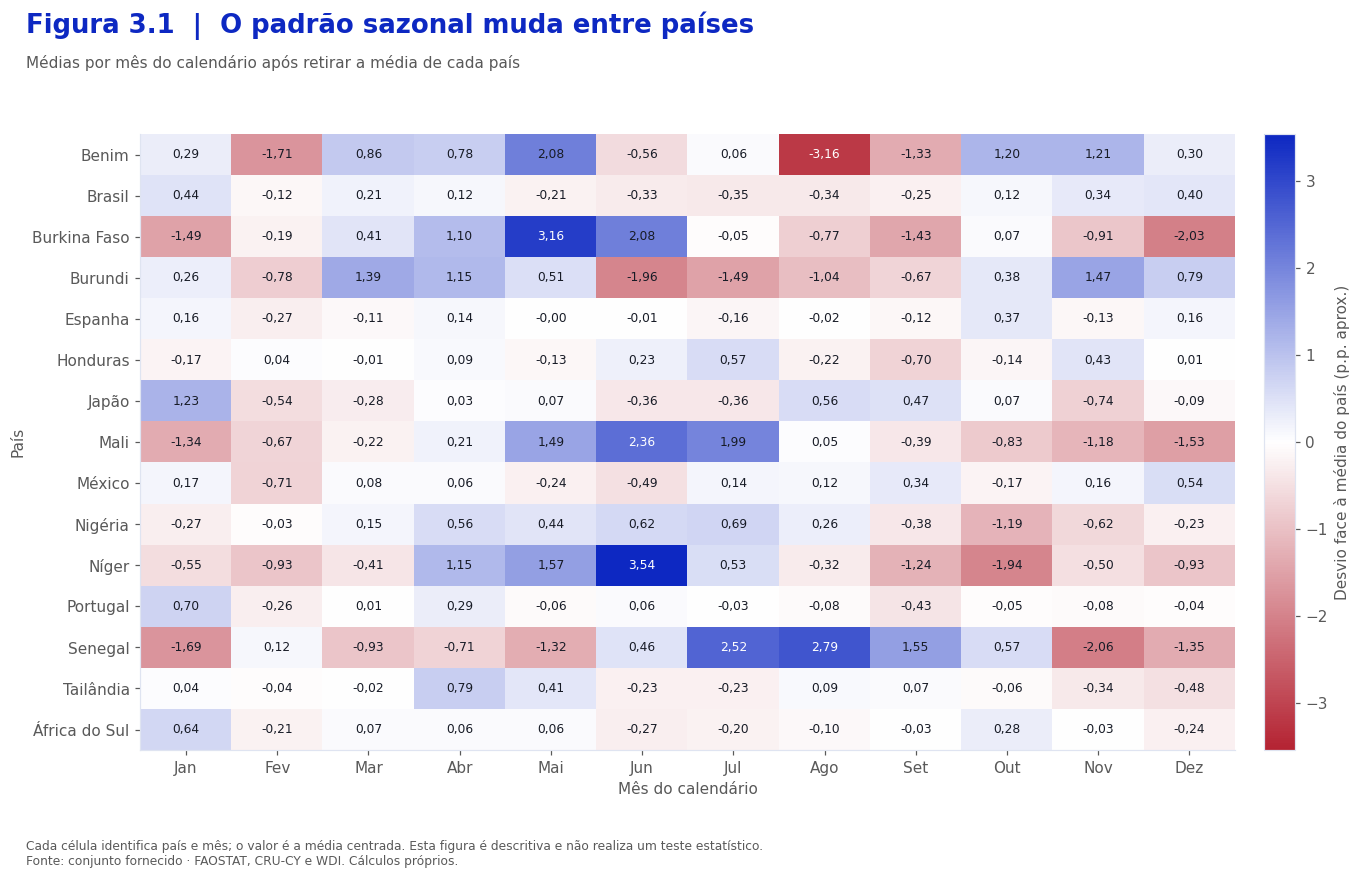

País,q Kruskal,q Wald/HAC 12,q Wald/HAC 24
Burundi,2.40e-06,2.42e-14,2.00e-31
Benim,8.65e-12,1.94e-23,8.21e-35
Burkina Faso,2.26e-16,2.38e-24,3.14e-43
Brasil,6.61e-06,5.93e-22,4.24e-31
Espanha,5.80e-04,2.21e-14,3.49e-26
Honduras,1.35e-08,3.84e-12,2.20e-33
Japão,2.85e-17,4.11e-68,8.59e-90
México,1.44e-05,1.20e-12,9.06e-15
Mali,3.87e-21,5.30e-42,3.67e-53
Níger,2.98e-17,3.01e-25,2.00e-40


In [2]:
perfil = perfil_sazonal(dados)
sazonalidade = testar_sazonalidade(dados)
mapa_sazonal(perfil, graficos)
colunas_sazonais = ["pais", "q_kruskal", "q_hac_12", "q_hac_24"]
nomes_sazonais = {
    "pais": "País",
    "q_kruskal": "q Kruskal",
    "q_hac_12": "q Wald/HAC 12",
    "q_hac_24": "q Wald/HAC 24",
}
tabela(
    sazonalidade[colunas_sazonais].rename(columns=nomes_sazonais),
    "Tabela 3.1 · Valores-p ajustados por BH (q)",
    formatos={
        nome: lambda valor: f"{valor:.2e}"
        for nome in nomes_sazonais.values()
        if nome != "País"
    },
)
csv(sazonalidade, tabelas / "01_testes_sazonalidade.csv")
csv(perfil.reset_index(), tabelas / "02_perfil_sazonal.csv")

In [3]:
from analise_resultados import resumir_perfil_sazonal

amplitudes = resumir_perfil_sazonal(perfil)
tabela(amplitudes, "Tabela 3.2 · Meses de máximo e mínimo e amplitude sazonal")
csv(amplitudes, tabelas / "12_amplitudes_sazonais.csv")

País,Mês máximo,Mês mínimo,Máximo centrado,Mínimo centrado,Amplitude (p.p. aprox.)
Níger,Jun,Out,"3,537","-1,940","5,476"
Benim,Mai,Ago,"2,082","-3,160","5,242"
Burkina Faso,Mai,Dez,"3,164","-2,033","5,197"
Senegal,Ago,Nov,"2,787","-2,064","4,851"
Mali,Jun,Dez,"2,361","-1,531","3,892"
Burundi,Nov,Jun,"1,465","-1,958","3,423"
Japão,Jan,Nov,"1,230","-0,745","1,975"
Nigéria,Jul,Out,"0,688","-1,194","1,882"
Honduras,Jul,Set,"0,570","-0,702","1,272"
Tailândia,Abr,Dez,"0,786","-0,475","1,261"


### Análise da sazonalidade

Os três procedimentos sinalizam os 15 países a 5%, incluindo Wald com HAC a 12 e a 24 meses. A significância em todos os países não significa que partilhem o mesmo padrão. No Níger, a média centrada atinge o máximo em junho e o mínimo em outubro, com amplitude de 5,48 pontos aproximados. No Benim, o máximo é em maio e o mínimo em agosto, com amplitude de 5,24.

Em Portugal, a amplitude é 1,12, com máximo em janeiro e mínimo em setembro; em Espanha é 0,64, com máximo em outubro e mínimo em fevereiro. O controlo de um único padrão mensal comum pode deixar por explicar estas diferenças nacionais. Deve comparar-se essa solução com indicadores mês × país, evitando termos redundantes com os restantes efeitos fixos.

Os valores-p muito baixos devem ser lidos juntamente com a amplitude dos padrões. São testes condicionais à regressão auxiliar e à escolha dos desfasamentos; não avaliam se a sazonalidade mudou durante os 26 anos.

## 2. Dependência temporal: antes e depois do calendário

Calculamos autocorrelações até 24 meses e Ljung–Box até ao desfasamento 12 em cada país. Comparamos a resposta original com os resíduos da regressão auxiliar de calendário e tendência. A continuidade mensal é verificada antes do cálculo.

Ljung–Box testa conjuntamente autocorrelações; não testa normalidade. Na série residual, os valores-p são referências exploratórias: a retirada de componentes estimadas e eventuais quebras tornam a calibração menos direta. Não são diagnósticos de resíduos de um modelo de painel final. [Documentação de Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html).

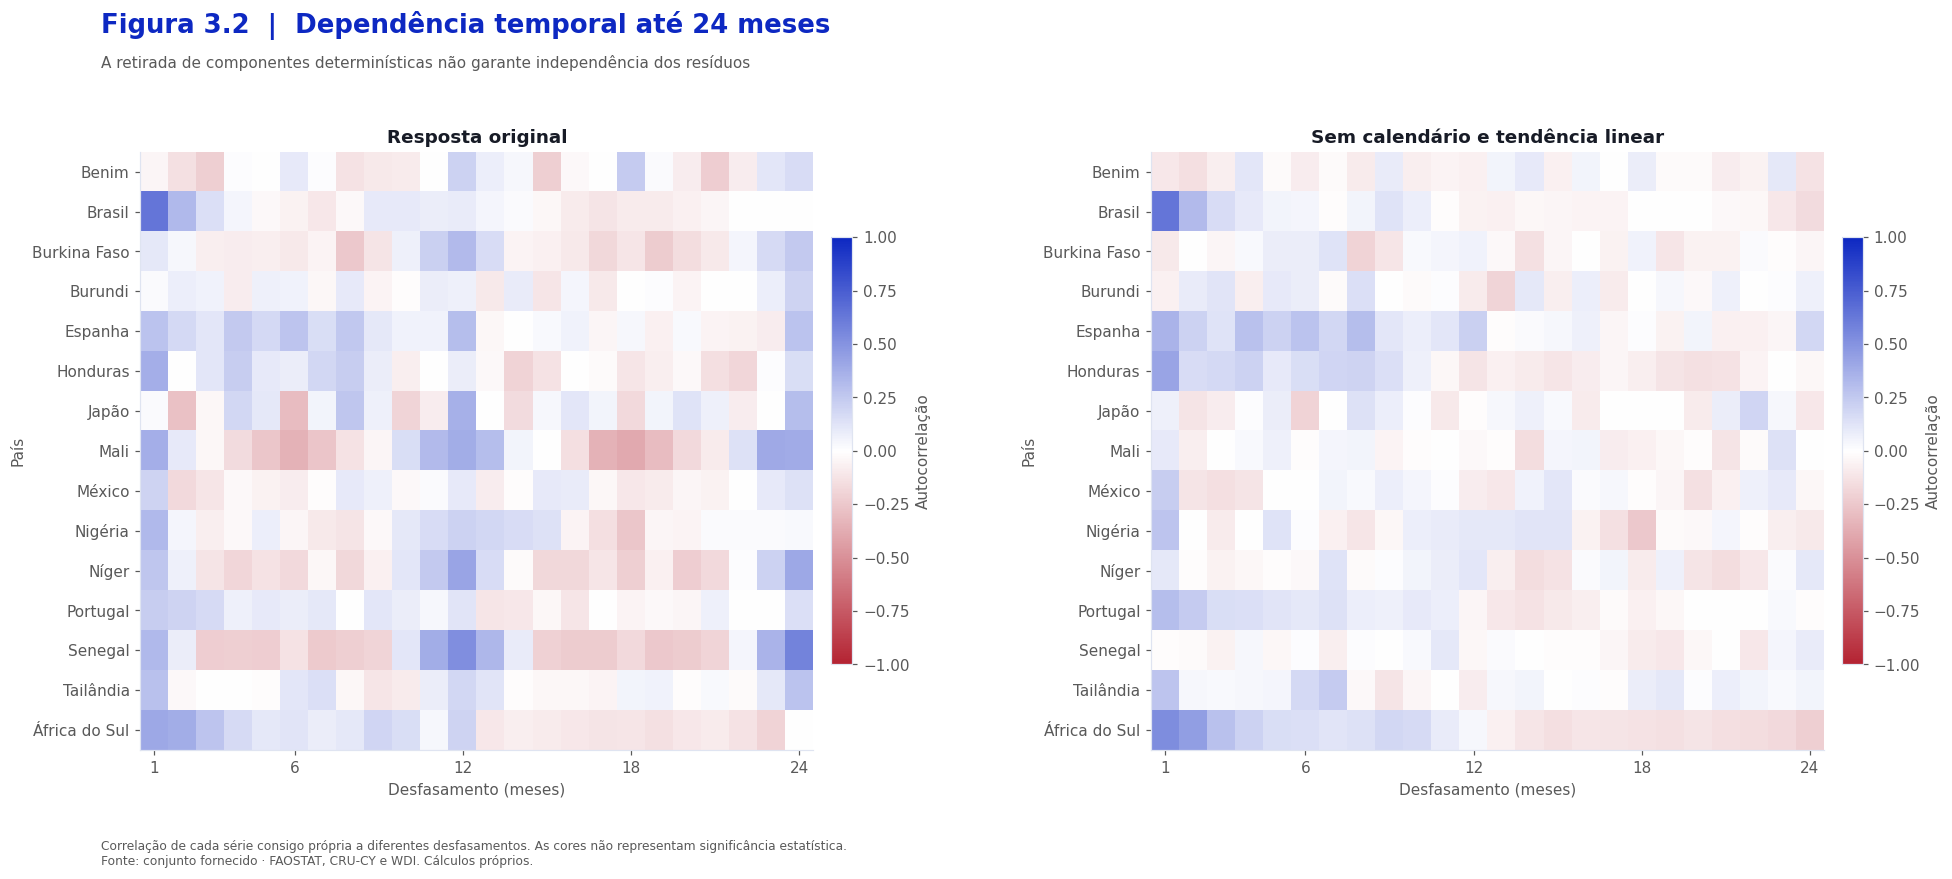

País,Série,ACF 1 mês,ACF 12 meses,q Ljung–Box
Burundi,Original,"0,016","0,068",2.16e-01
Burundi,Sem calendário/tendência,"-0,066","-0,091",2.18e-02
Benim,Original,"-0,043","0,210",2.03e-06
Benim,Sem calendário/tendência,"-0,107","-0,064",9.98e-03
Burkina Faso,Original,"0,106","0,319",1.42e-12
Burkina Faso,Sem calendário/tendência,"-0,099","0,060",2.26e-03
Brasil,Original,"0,638","0,093",1.31e-31
Brasil,Sem calendário/tendência,"0,636","-0,058",5.14e-31
Espanha,Original,"0,278","0,303",7.47e-25
Espanha,Sem calendário/tendência,"0,350","0,216",2.55e-31


In [4]:
dependencia, acfs = diagnosticar_dependencia(dados)
mapa_autocorrelacao(acfs, graficos)
dependencia_visivel = dependencia.rename(
    columns={
        "pais": "País",
        "serie": "Série",
        "acf_1": "ACF 1 mês",
        "acf_12": "ACF 12 meses",
        "q_lb": "q Ljung–Box",
    }
)
dependencia_visivel["Série"] = dependencia_visivel["Série"].replace(
    {"original": "Original", "sem_calendario_tendencia": "Sem calendário/tendência"}
)
tabela(
    dependencia_visivel[["País", "Série", "ACF 1 mês", "ACF 12 meses", "q Ljung–Box"]],
    "Tabela 3.3 · Autocorrelação e teste conjunto",
    formatos={"q Ljung–Box": lambda valor: f"{valor:.2e}"},
)
csv(dependencia, tabelas / "03_dependencia_temporal.csv")
csv(acfs, tabelas / "04_acf_1_a_24_meses.csv")

### Análise da dependência temporal

Ljung–Box sinaliza 14 séries originais. Depois de retirar calendário e tendência linear, mantém a sinalização em 12. Mali, Níger e Senegal deixam de ser sinalizados; Burundi passa a apresentar q = 0,022. A comparação não equivale, portanto, a identificar dois países onde o problema desapareceu.

No Senegal, a autocorrelação a 12 meses desce de 0,516 para −0,039; no Mali, de 0,381 para −0,024. A componente anual explica uma parte considerável da repetição nestas séries. No Brasil, a autocorrelação a um mês permanece praticamente inalterada: 0,638 antes e 0,636 depois. Existe persistência de curto prazo que o calendário não absorve.

Em Portugal, a autocorrelação a um mês sobe de 0,229 para 0,302 após a transformação. Retirar componentes determinísticas pode revelar dependência antes parcialmente compensada por outros movimentos. Para a modelação, estes resultados justificam tratar a correlação dentro dos países e voltar a examinar os resíduos dos modelos finais. Os valores-p sobre resíduos desta regressão auxiliar continuam a ser diagnósticos exploratórios.

## 3. Movimentos comuns e correlações entre países

Retiramos a média do mesmo país e mês do calendário e calculamos a média e a mediana transversais dos desvios. Os pares usam a mesma janela de meses. Esta centração não retira tendências nem identifica causalmente um choque mundial: correlações podem refletir fatores regionais ou acontecimentos não observados. O perfil usa toda a amostra e teria de ser recalculado apenas no treino num exercício de previsão.

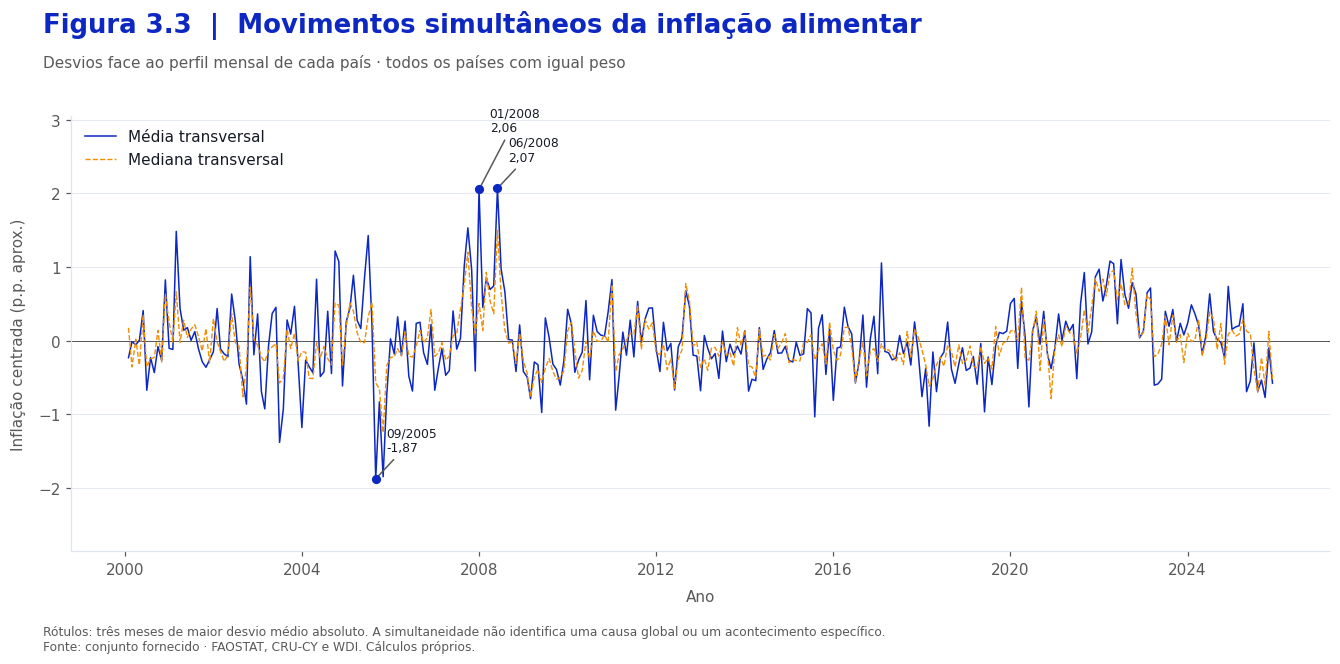

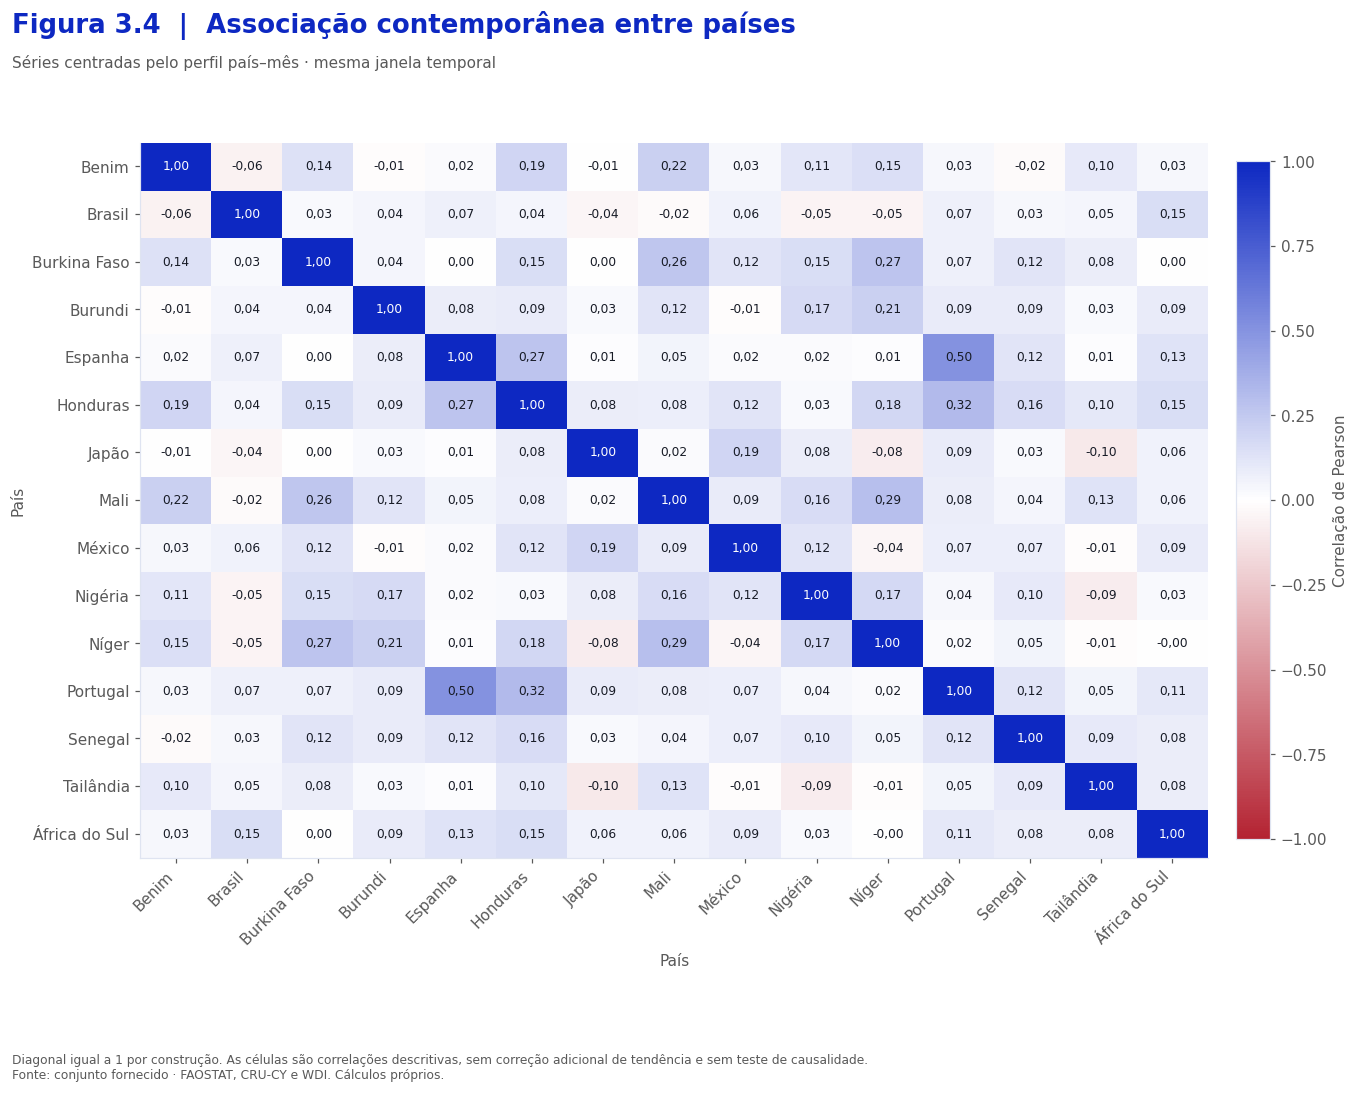

Mês,Média transversal,Mediana transversal,Países com desvio positivo,DP entre países
06/2008,"2,069","1,500","14,000","1,882"
01/2008,"2,055","0,505","12,000","2,944"
09/2005,"-1,874","-0,574","4,000","2,933"
11/2005,"-1,846","-1,246","3,000","2,196"
10/2007,"1,533","1,202","12,000","2,187"
03/2001,"1,485","0,664","12,000","2,062"
07/2005,"1,428","0,329","12,000","3,261"
07/2003,"-1,380","-0,573","1,000","2,262"


In [5]:
choques, correlacao = medir_choques_comuns(dados)
serie_choques(choques, graficos)
mapa_correlacoes(correlacao, graficos)
maiores_choques = choques.assign(absoluto=choques.media_transversal.abs())
maiores_choques = (
    maiores_choques.nlargest(8, "absoluto").drop(columns="absoluto").reset_index()
)
choques_visiveis = maiores_choques.rename(
    columns={
        "data": "Mês",
        "media_transversal": "Média transversal",
        "mediana_transversal": "Mediana transversal",
        "paises_positivos": "Países com desvio positivo",
        "dp_entre_paises": "DP entre países",
    }
)
choques_visiveis["Mês"] = choques_visiveis["Mês"].dt.strftime("%m/%Y")
tabela(choques_visiveis, "Tabela 3.4 · Maiores desvios médios absolutos")
csv(choques.reset_index(), tabelas / "05_choques_comuns.csv")
csv(correlacao.reset_index(), tabelas / "06_correlacoes_paises.csv")

### Análise dos movimentos comuns

A correlação mediana entre os 105 pares de países é 0,070. Há 89 pares positivos, mas muitos com associações fracas. O par Espanha–Portugal destaca-se com 0,504; Honduras–Portugal apresenta 0,318 e Mali–Níger 0,293. A intensidade da associação varia entre pares, pelo que um único fator comum não resume toda a relação entre países.

Em junho de 2008, o desvio médio transversal é +2,069, a mediana é +1,500 e 14 dos 15 países têm desvio positivo. O movimento nesse mês abrange quase toda a amostra. Em janeiro de 2008, a média é semelhante (+2,055), mas a mediana é apenas +0,505: alguns países contribuem com desvios muito maiores do que os restantes.

Em setembro de 2005, o desvio médio é −1,874 e a mediana −0,574; só quatro países têm desvio positivo. As diferenças entre média, mediana e número de sinais ajudam a distinguir meses amplamente partilhados de episódios concentrados. Estes resultados justificam comparar efeitos de data completa, sem atribuir automaticamente os movimentos a um acontecimento económico específico.

## 4. Extremos: cálculo, contexto nacional e sensibilidade

Recalculamos a inflação a partir do IPC do mês anterior e do mês atual, verificando a distância de um mês. Comparamos a sinalização IQR global com a calculada dentro de cada país. Um caso pode satisfazer ambas, mas é contado uma só vez na união.

A concordância com o IPC publicado confirma a transformação numérica. Não verifica alterações de cabaz, metodologia ou erros nas entidades produtoras. Os sinalizadores A/X também não certificam ausência de estimativas a montante.

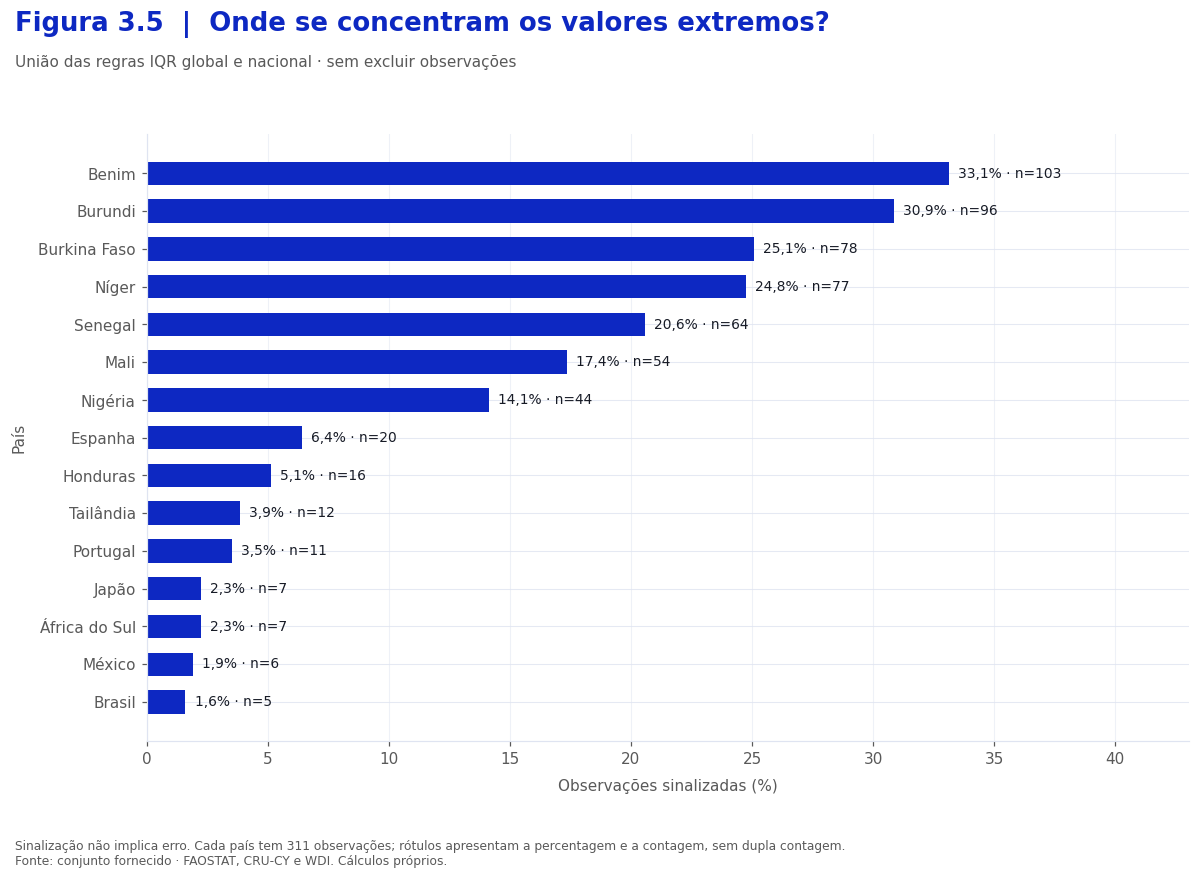

País,Mês,Inflação (aprox. %),Flag FAO,IPC anterior,IPC atual,IQR global,IQR nacional
Nigéria,07/2005,"11,880",X,"36,791","41,432",True,True
Burundi,08/2004,"10,693",X,"30,912","34,401",True,True
Burkina Faso,05/2003,"10,520",X,"61,191","67,979",True,True
Burundi,02/2017,"10,320",X,"122,661","135,996",True,True
Nigéria,04/2001,"10,239",A,"19,378","21,467",True,True
Burundi,05/2004,"10,236",X,"31,750","35,172",True,True
Níger,06/2005,"10,226",X,"70,164","77,719",True,True
Benim,02/2022,"-10,135",X,"116,430","105,208",True,True
Burkina Faso,05/2008,"9,605",X,"78,201","86,085",True,True
Burundi,11/2022,"9,095",X,"186,594","204,359",True,True


In [6]:
conferencia = conferir_inflacao(dados, pasta_dados)
extremos, resumo_extremos = analisar_extremos(conferencia)
extremos_por_pais(resumo_extremos, graficos)
casos = extremos.assign(absoluto=extremos[Y].abs()).nlargest(12, "absoluto")
colunas_casos = [
    "pais",
    "data",
    Y,
    "flag_ipc_faostat",
    "ipc_anterior",
    "ipc_alimentar_2015_100",
    "iqr_global",
    "iqr_pais",
]
casos_visiveis = casos[colunas_casos].rename(
    columns={
        "pais": "País",
        "data": "Mês",
        Y: "Inflação (aprox. %)",
        "flag_ipc_faostat": "Flag FAO",
        "ipc_anterior": "IPC anterior",
        "ipc_alimentar_2015_100": "IPC atual",
        "iqr_global": "IQR global",
        "iqr_pais": "IQR nacional",
    }
)
casos_visiveis["Mês"] = casos_visiveis["Mês"].dt.strftime("%m/%Y")
tabela(casos_visiveis, "Tabela 3.5 · Maiores valores absolutos sinalizados")
csv(extremos, tabelas / "07_extremos_conferidos.csv")
csv(resumo_extremos, tabelas / "08_extremos_por_pais.csv")

### Análise da sinalização dos extremos

A união das regras global e nacional identifica 600 observações, 12,9% do painel. A regra global sinaliza 519 e a nacional 185; 104 casos pertencem a ambas. No Benim, há 103 sinalizações globais e apenas três nacionais. Em Espanha ocorre o inverso: uma global e 20 nacionais. O limite global assinala sobretudo a elevada dispersão de algumas séries; o limite nacional identifica desvios relativos à distribuição de cada país.

Benim, Burundi, Burkina Faso, Níger, Senegal e Mali concentram 472 dos 600 casos (78,7%). Esta concentração ajuda a explicar por que a eliminação indiscriminada mudaria a composição da amostra. Portugal tem 11 casos sinalizados na união, e o Brasil tem cinco.

O recálculo da resposta a partir do IPC confirma os valores dentro da tolerância de 10⁻⁹. O máximo da Nigéria em julho de 2005 e o mínimo do Benim em fevereiro de 2022 não resultam de uma discrepância na transformação usada neste trabalho. A confirmação dos registos pelas fontes continua necessária antes de os classificar como erros.

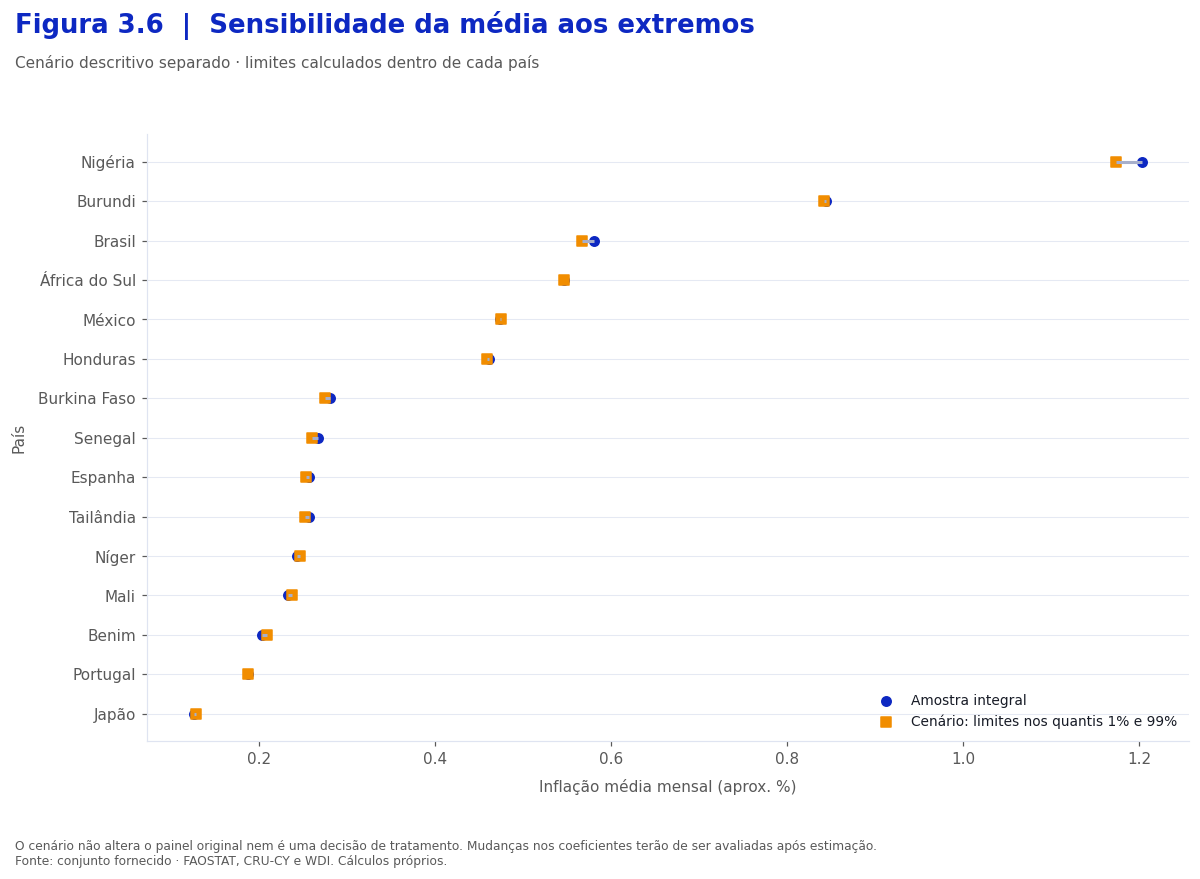

In [7]:
sensibilidade = sensibilidade_extremos(dados)
sensibilidade_da_media(sensibilidade, graficos)
csv(sensibilidade, tabelas / "09_sensibilidade_descritiva.csv")
erro_maximo = conferencia.erro_absoluto.max()
maior_mudanca = sensibilidade.diferenca_media.abs().max()

### O que muda no cenário de sensibilidade

Ao limitar os valores aos quantis nacionais de 1% e 99%, a média da Nigéria passa de 1,203 para 1,174, uma redução de 0,029 pontos aproximados por mês. É a maior alteração absoluta entre as médias nacionais. O desvio padrão desce de 1,725 para 1,522, cerca de 11,8%.

Em Portugal, a média praticamente não muda (0,18742 para 0,18727), mas o desvio padrão desce de 0,668 para 0,618, cerca de 7,5%. Neste cenário, os extremos afetam mais a dispersão do que o nível médio. A estabilidade da média não demonstra estabilidade dos coeficientes ou da inferência; isso terá de ser avaliado nos modelos.

O painel principal conserva todos os valores. Os limites de quantis foram aplicados apenas numa cópia usada para esta comparação descritiva.

## 5. Amostras comparáveis para os modelos

São definidas duas especificações: desenvolvimento e agricultura. Cada uma tem as mesmas covariáveis em pooled OLS, efeitos fixos e efeitos aleatórios. A amostra comum às duas permite também comparações diretas entre as especificações.

Os ficheiros em `dados/modelacao/` contêm os valores originais nas colunas selecionadas. A centração de variáveis económicas, se adotada depois, deve incluir a reconstrução das interações e o registo das médias usadas. Esta etapa prepara as amostras; ainda não estima os modelos.

In [8]:
amostras, comparacao = preparar_amostras(dados)
pasta_modelacao = raiz / "dados" / "modelacao"
pasta_modelacao.mkdir(parents=True, exist_ok=True)
for nome, amostra in amostras.items():
    csv(amostra, pasta_modelacao / f"amostra_{nome}.csv")
tabela(
    comparacao.drop(columns="Covariáveis"),
    "Tabela 3.6 · Amostra por especificação",
    precisao=0,
)
for nome, covariaveis in ESPECIFICACOES.items():
    rotulos = ", ".join((VAR_LABELS[coluna] for coluna in covariaveis))
    display(Markdown(f"**{nome.capitalize()}:** {rotulos}."))
csv(comparacao, tabelas / "10_comparabilidade_especificacoes.csv")

Especificação,Observações,Países,Meses,Excluídas
desenvolvimento,4 665,15,311,0
agricultura,4 665,15,311,0


**Desenvolvimento:** Anomalia térmica, Défice hídrico de 3 meses, Log PIB real por habitante (t−1), Calor × log PIB.

**Agricultura:** Anomalia térmica, Défice hídrico de 3 meses, Peso agrícola no PIB (t−1), Calor × peso agrícola.

### Consequência para a comparação dos modelos

As especificações de desenvolvimento e de agricultura mantêm as mesmas 4 665 observações, os 15 países e os 311 meses. Não existem perdas por omissos na seleção atual. Os ficheiros em `dados/modelacao/` permitem usar a mesma chave país–data nas comparações.

A exploração encontrou pouca variação económica dentro dos países e forte sazonalidade nacional. Ao comparar pooled OLS, efeitos fixos e aleatórios, terá de manter-se o mesmo conjunto de covariáveis e o mesmo tratamento temporal dentro de cada comparação. Caso se acrescentem desfasamentos, todas as alternativas comparáveis devem usar a interseção dos meses efetivamente disponíveis. Ainda não há coeficientes estimados que permitam escolher um modelo vencedor.

## 6. Alterações propostas, evidência e critérios de verificação

A tabela seguinte transforma os diagnósticos em tarefas concretas. São **propostas para a modelação**: não se deve assinalá-las como concluídas antes de estimar e validar os modelos correspondentes. As melhorias de código, rotulagem, apresentação e organização de ficheiros já estão aplicadas.

In [9]:
alteracoes = plano_alteracoes(
    sazonalidade, dependencia, extremos, correlacao, len(amostras["comum"])
)
alteracoes["Estado"] = "Proposta para a modelação"
from estilo_iscte import apresentar_plano

apresentar_plano(alteracoes)
csv(alteracoes, tabelas / "11_plano_de_alteracoes.csv")

ID,Prioridade,Tema,Estado
A01,Alta,Sazonalidade,Proposta para a modelação
A02,Alta,Dependência temporal,Proposta para a modelação
A03,Alta,Choques comuns,Proposta para a modelação
A04,Alta,Extremos,Proposta para a modelação
A05,Alta,Comparabilidade,Proposta para a modelação
A06,Média,Interações e unidades,Proposta para a modelação
A07,Média,Disponibilidade em tempo real,Proposta para a modelação


### A01 · Sazonalidade

**Evidência:** 15/15 países com q < 0,05 no Wald/HAC(12).

**Alteração proposta:** Comparar uma especificação com indicadores do mês do calendário; avaliar diferenças sazonais entre países.

**Como verificar:** Comparar os resíduos e repetir os diagnósticos após estimação.

### A02 · Dependência temporal

**Evidência:** 14/15 países sinalizados na resposta original.

**Alteração proposta:** Usar inferência que considere dependência dentro do país e verificar dinâmica residual.

**Como verificar:** Reexaminar ACF e resíduos; explicitar limites de apenas 15 grupos.

### A03 · Choques comuns

**Evidência:** Correlação mediana entre pares: 0.070.

**Alteração proposta:** Comparar modelos com e sem efeitos fixos de data completa, mantendo a mesma amostra.

**Como verificar:** Comparar estabilidade dos coeficientes e dependência transversal dos resíduos.

### A04 · Extremos

**Evidência:** 600 observações sinalizadas; transformação do IPC conferida.

**Alteração proposta:** Manter a amostra principal; confirmar registos junto da fonte e usar sensibilidade separada.

**Como verificar:** Apresentar resultados integrais e de sensibilidade; justificar qualquer exclusão.

### A05 · Comparabilidade

**Evidência:** 4665 observações na amostra comum.

**Alteração proposta:** Reutilizar exatamente os mesmos pares país–data e covariáveis para pooled, FE e RE dentro de cada especificação.

**Como verificar:** Confirmar índices, número de linhas e controlos de calendário antes de comparar.

### A06 · Interações e unidades

**Evidência:** Interações com variáveis económicas anuais não centradas.

**Alteração proposta:** Centrar as covariáveis económicas como reparametrização e reconstruir interações; guardar as médias usadas.

**Como verificar:** Confirmar previsões equivalentes e explicitar a interpretação dos efeitos principais.

### A07 · Disponibilidade em tempo real

**Evidência:** O desfasamento anual não comprova a data de publicação.

**Alteração proposta:** Documentar que a análise é retrospetiva; recolher versões históricas se o objetivo for previsão em tempo real.

**Como verificar:** Registar datas de publicação antes de afirmar disponibilidade histórica.

## Limites das conclusões

Os resultados permitem documentar diferenças nacionais, mudanças por períodos, sazonalidade, dependência e associações contemporâneas fracas entre os indicadores climáticos e a resposta. Para atribuir essas relações ao clima, falta estimar modelos condicionais, considerar desfasamentos e verificar os seus resíduos.

As médias nacionais ocultam diferenças regionais, a classificação de rendimento é atual e os dados foram recolhidos em versões revistas. A seleção de 15 países também não permite generalizar as médias deste painel a todos os países. As próximas estimativas devem explicitar estas restrições e confrontar os resultados integrais com as análises de sensibilidade.